## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kathryn Choi

**Date:** 10/22/26

In [ ]:
# Your Phase 1 solution to the problem goes here.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


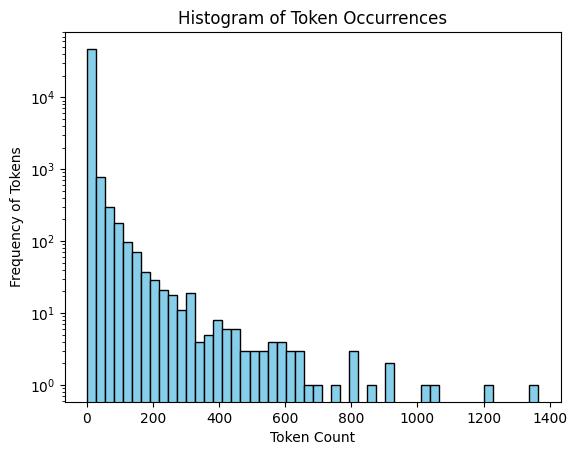

In [20]:
# Question 1

# Running given code chunk
import pickle

with open('/content/drive/MyDrive/Semester 5 - Fall 2026/DS 3001 - Intro to Machine Learning/A05 - PCA/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# Plotting histogram of token occurrences
import matplotlib.pyplot as plt

occurrences = [count for token, count in token_freq]
plt.hist(occurrences, bins=50, color='skyblue', log=True, edgecolor='black')
plt.xlabel('Token Count')
plt.ylabel('Frequency of Tokens')
plt.title('Histogram of Token Occurrences')
plt.show()


# The histogram is very right-skewed, meaning that there are many "rare" tokens that are only used a few times and only a few tokens appear regularly.

In [21]:
# Question 2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('/content/drive/MyDrive/Semester 5 - Fall 2026/DS 3001 - Intro to Machine Learning/A05 - PCA/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop(columns=['Email Type'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Running regression
model = LinearRegression()
model.fit(X_train, y_train)

# Finding R^2
train_R2 = model.score(X_train, y_train)
test_R2 = model.score(X_test, y_test)

# Determining largest coefficients
coefs = pd.Series(model.coef_, index=X.columns)
largest_coefs = coefs.abs().sort_values(ascending=False)

print(f"R^2 for Training Set: {train_R2:.4f}")
print(f"R^2 for Test Set: {test_R2:.4f}")
print(f"Largest Coefficients: {largest_coefs.head()}")

R^2 for Training Set: 0.7670
R^2 for Test Set: 0.6659
Largest Coefficients: intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
dtype: float64


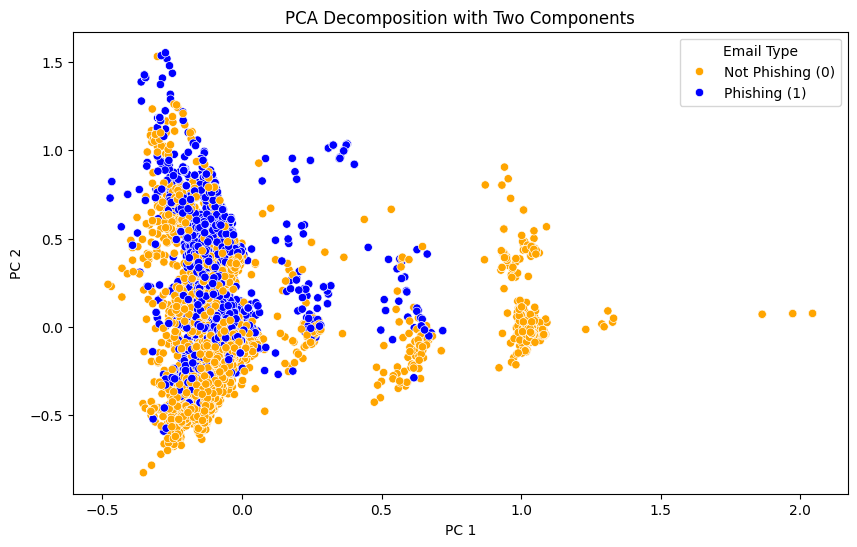

In [23]:
# Question 3
import numpy as np
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
pca_df['Email Type'] = pca_df['Email Type'].map({0: 'Not Phishing (0)', 1: 'Phishing (1)'})

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Email Type',
    palette={'Not Phishing (0)': 'orange', 'Phishing (1)': 'blue'},
    data=pca_df
)
plt.title("PCA Decomposition with Two Components")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()

# Based on the scatterplot, there seems to be some distinct vertical clusters and phishing emails tend to populate the left side of
# the graph while non-phishing emails populate the left and right sides of the graph. Using the graph, an email with low PC 1 values
# and high PC 2 values is likely to be a scam email while higher PC 1 values in general are more likely to not be scam emails.

In [24]:
# Question 4
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

# PCA
pca_Q4 = PCA(n_components=2610, random_state=42)
X_pca_Q4 = pca_Q4.fit_transform(X)

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca_Q4, y, test_size=0.2, random_state=42)

# Running regression
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train_pca)

# Finding R^2
train_R2_pca = model_pca.score(X_train_pca, y_train_pca)
test_R2_pca = model_pca.score(X_test_pca, y_test_pca)

print(f"R^2 for PCA Training Set: {train_R2_pca:.4f}")
print(f"R^2 for PCA Test Set: {test_R2_pca:.4f}")


# The R^2 for the PCA training set is 0.7662 whereas the original training set R^2 was 0.7670, meaning that the original training set
# explained slightly more variance. The R^2 for the PCA test set is 0.6684 whereas the original test set R^2 was 0.6659, meaning that
# the PCA test explained more variance than the original.

R^2 for PCA Training Set: 0.7662
R^2 for PCA Test Set: 0.6684


**Question 5**

Using principal components rather than the original data to run this high-dimensional regression is advantageous because it helps to eliminate multicollinearity since many tokens are highly correlated with each other, so PCA transforms features into an orthogonal and uncorrelated set. Principal components also help to filter out noise by dropping components with very low, irrelevant variance.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]